# 01 · Exploratory Data Analysis — Used cars in Jordan 🇯🇴

**Goal of this notebook:** understand the data *before* building any model.
EDA answers three questions:
1. **Is the data trustworthy?** (missing values, duplicates, impossible values)
2. **What does the target look like?** (the price distribution decides how we model it)
3. **Which features move the price?** (this guides feature engineering)

**Data:** JUCars-2024 — 10,921 listings scraped in 2024 from OpenSooq, Dubizzle, Motory, AutoBeeb and Dooz.
Thalji & Tahat, *Data in Brief* 66 (2026), [doi:10.1016/j.dib.2026.112682](https://doi.org/10.1016/j.dib.2026.112682), CC BY 4.0.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

from jocars.config import FIGURES, TARGET
from jocars.data import load_raw
from jocars.plotting import set_style, jod, SERIES, SEQ, TEXT_2

set_style()
FIGURES.mkdir(parents=True, exist_ok=True)
raw = load_raw()
raw.shape

(10921, 22)

## 1 · First look: shape, types, a few rows

In [2]:
raw.head()

,price_value_JOD,make,model,year,mileage_km,mileage_text,body_type,condition,transmission,fuel_type,...,interior_color,seats,city,feat_insurance,feat_carcustoms,feat_license,feat_paintcondition,feat_body_condition,feat_battery_capacity,feat_battery_range
0,13500.0,Honda,Accord,2017,154999.0,"150,000 - 159,999",Sedan,Used,Automatic,Hybrid,...,Black,5,Amman,Compulsory Insurance,With Customs,Licensed,Partially repainted,Good (body only has minor blemishes),NaN,NaN
1,22700.0,Mercedes Benz,C-Class,2016,134999.0,"130,000 - 139,999",Sedan,Used,Automatic,Plug-in - Hybrid,...,Black,5,Amman,Compulsory Insurance,With Customs,Licensed,Original Paint,Excellent with no defects,NaN,NaN
2,4700.0,Mazda,2,2013,104999.0,"100,000 - 109,999",HatchBack,Used,Automatic,Gasoline,...,Black,4,Amman,Compulsory Insurance,With Customs,Licensed,Total repaint,Good (body only has minor blemishes),NaN,NaN
3,12700.0,Hyundai,Ioniq,2019,94999.0,"90,000 - 99,999",Sedan,Used,Automatic,Hybrid,...,Grey,5,Amman,Compulsory Insurance,With Customs,Licensed,Original Paint,Excellent with no defects,NaN,NaN
4,13700.0,Toyota,Corolla,2021,34999.0,"30,000 - 39,999",Sedan,Used,Automatic,Gasoline,...,Beige,5,Amman,Compulsory Insurance,With Customs,Licensed,Original Paint,Excellent with no defects,NaN,NaN


In [3]:
raw.dtypes

price_value_JOD          float64
make                         str
model                        str
year                         str
mileage_km               float64
mileage_text                 str
body_type                    str
condition                    str
transmission                 str
fuel_type                    str
engine_type                  str
color                        str
interior_color               str
seats                        str
city                         str
feat_insurance               str
feat_carcustoms              str
feat_license                 str
feat_paintcondition          str
feat_body_condition          str
feat_battery_capacity        str
feat_battery_range           str
dtype: object

Almost everything is **text (categorical)**. Even `year` and `seats` are text, because some values are
`"Older than 1970"` and `"More than 9"`. Only `price_value_JOD` and `mileage_km` are numbers.

## 2 · Data quality: empty rows, duplicates, missing values

In [4]:
n_empty = raw.isna().all(axis=1).sum()
n_dupes = raw.dropna(how="all").duplicated().sum()
n_no_price = raw.dropna(how="all")[TARGET].isna().sum()
print(f"fully empty rows : {n_empty}")
print(f"duplicate rows   : {n_dupes}")
print(f"rows with no price (after dropping empty): {n_no_price}")

fully empty rows : 636
duplicate rows   : 64
rows with no price (after dropping empty): 546


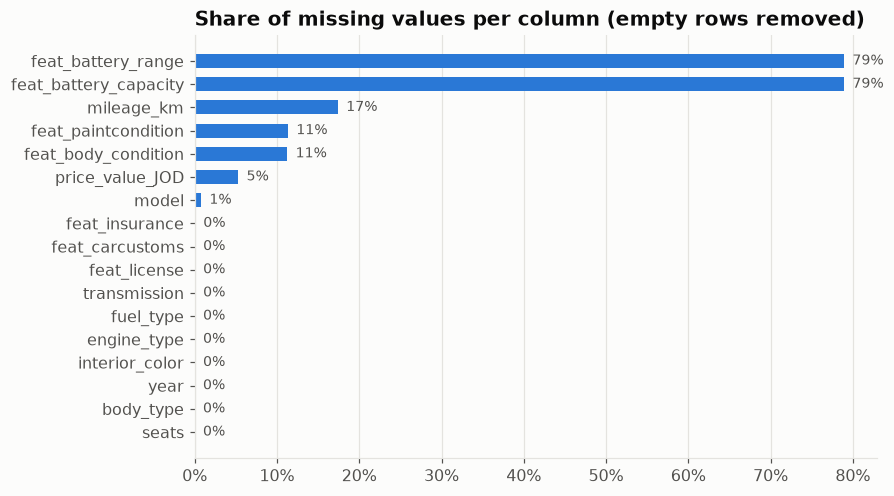

In [5]:
df = raw.dropna(how="all")
missing = df.isna().mean().sort_values()
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(missing.index, missing.values, color=SEQ, height=0.6)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Share of missing values per column (empty rows removed)")
ax.grid(axis="y", visible=False)
for y, v in enumerate(missing.values):
    ax.text(v + 0.01, y, f"{v:.0%}", va="center", color=TEXT_2, fontsize=9)
fig.savefig(FIGURES / "fig01_missing_values.png"); plt.show()

**Reading the chart:**
- `feat_battery_*` are ~80% missing — **that is not an error**: petrol cars have no battery. Missing here *means something* ("not electric"), so later we will fill it with a category like `"None"` instead of guessing.
- `mileage_km` is ~20% missing, but **only for used cars** (new cars have 0 km). We'll let the model know it was missing.
- Rows without a price are useless for training: a model learns from (features → known answer).

## 3 · The target: price

In [6]:
df = raw.dropna(how="all").dropna(subset=[TARGET]).drop_duplicates().copy()
df[TARGET].describe().round(0)

count       9708.0
mean       15774.0
std       108694.0
min          550.0
25%         4400.0
50%         9900.0
75%        16900.0
max      7000000.0
Name: price_value_JOD, dtype: float64

The mean (≈15.8k) is far above the median (9.9k) and the max is **7,000,000 JOD**. Let's look at the extremes.

In [7]:
cols = [TARGET, "make", "model", "year", "condition"]
print("Most expensive listings:")
display(df.nlargest(10, TARGET)[cols])
print("Cheapest listings:")
display(df.nsmallest(8, TARGET)[cols])

Most expensive listings:


,price_value_JOD,make,model,year,condition
2569,7000000.0,Mitsubishi,Pajero,2011,Used
2115,6700000.0,Mercedes Benz,CLK-Class,2000,Used
5329,3333365.0,Seat,Arona,2001,Used
73,1125555.0,Land Rover,Range Rover,2021,Used
2716,1000000.0,Toyota,Other,1998,Used
2974,1000000.0,Toyota,Corolla,2021,Used
4677,1000000.0,Volkswagen,Caddy,2020,Used
4761,999999.0,Nissan,Sunny,2016,Used
4857,999999.0,Chevrolet,Tahoe,2008,Used
4860,999999.0,Land Rover,LR4,2014,Used


Cheapest listings:


,price_value_JOD,make,model,year,condition
186,550.0,Neta,V,2022,Used
1435,550.0,Opel,Kadett,1991,Used
2647,550.0,Kia,Sephia,1997,Used
3069,550.0,Volkswagen,Golf,1985,Used
5934,550.0,Great Wall,C 30,2011,Used
6176,550.0,Changan,E-Star,2021,Used
7784,550.0,Changan,E-Star,2021,Used
8275,550.0,Kia,Cerato,2016,Used


**Domain sense beats statistics here.** A 2001 Hyundai Verna is not worth 444,440 JOD, and a 2011 Pajero is not
7 million. Values like `999999` / `1000000` are **placeholder prices** sellers type to avoid showing a real price.
At the other end, a 2020 Tesla for 999 JOD is probably a *down payment* or a "call me" price.
➡️ In the cleaning phase we will keep a **plausible price range** and explain the cut-offs.

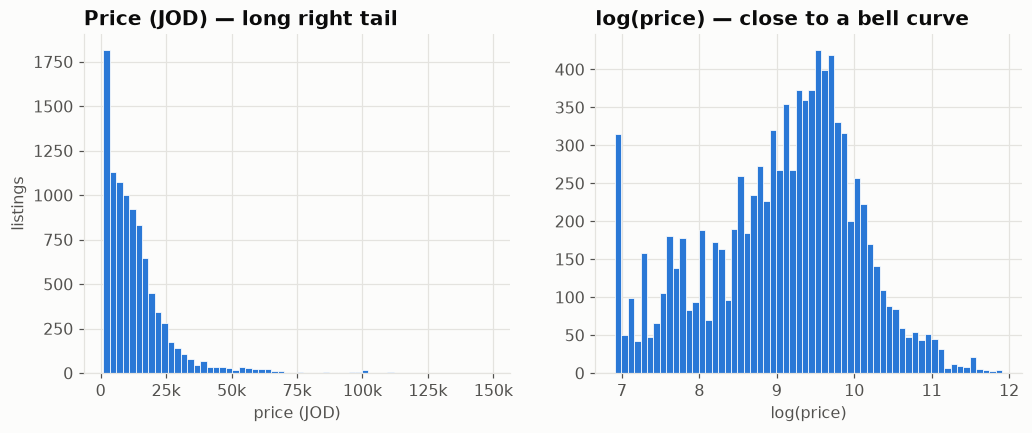

In [8]:
plausible = df[df[TARGET].between(1000, 150000)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(plausible[TARGET], bins=60, color=SEQ, edgecolor="white", linewidth=0.5)
axes[0].xaxis.set_major_formatter(FuncFormatter(jod))
axes[0].set_title("Price (JOD) — long right tail")
axes[0].set_xlabel("price (JOD)"); axes[0].set_ylabel("listings")
axes[1].hist(np.log(plausible[TARGET]), bins=60, color=SEQ, edgecolor="white", linewidth=0.5)
axes[1].set_title("log(price) — close to a bell curve")
axes[1].set_xlabel("log(price)")
fig.savefig(FIGURES / "fig02_price_distribution.png"); plt.show()

**Why log?** Price errors are *relative*: being off by 1,000 JOD is huge for a 3,000 JOD car and tiny for a 60,000 JOD car.
Training on `log(price)`:
- makes the distribution symmetric, so expensive cars don't dominate the loss,
- turns the model's errors into **percentage-like** errors,
- we convert back with `exp()` when we predict.

## 4 · Brand: who holds value?

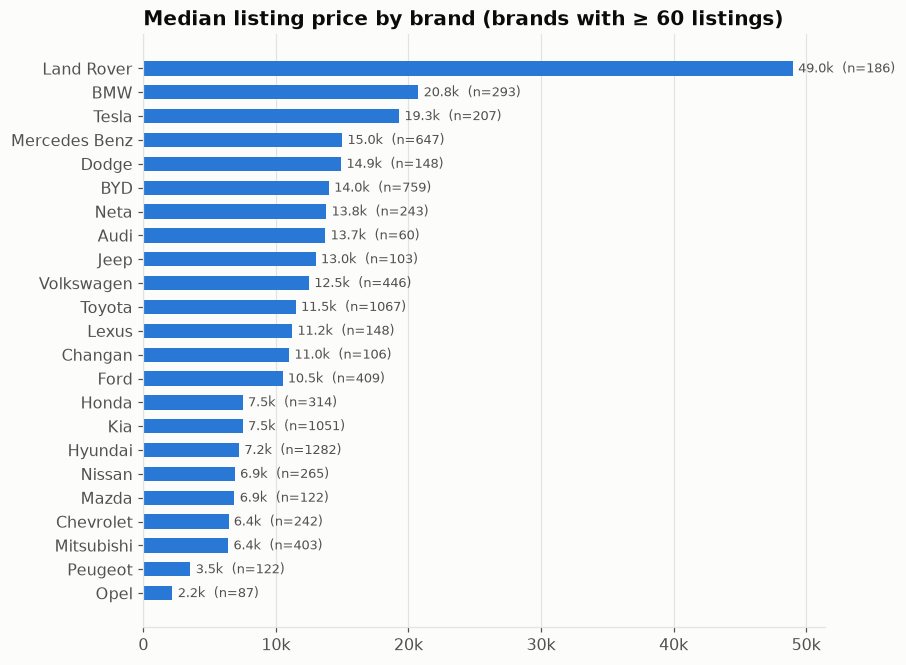

In [9]:
by_make = (plausible.groupby("make")[TARGET].agg(["median", "count"])
           .query("count >= 60").sort_values("median"))
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(by_make.index, by_make["median"], color=SEQ, height=0.6)
ax.xaxis.set_major_formatter(FuncFormatter(jod))
ax.grid(axis="y", visible=False)
ax.set_title("Median listing price by brand (brands with ≥ 60 listings)")
for y, (m, n) in enumerate(zip(by_make["median"], by_make["count"])):
    ax.text(m + 400, y, f"{m/1000:.1f}k  (n={n})", va="center", color=TEXT_2, fontsize=8.5)
fig.savefig(FIGURES / "fig03_price_by_brand.png"); plt.show()

Brand matters a lot (Daewoo ~1.3k vs Land Rover ~49k). Note that **Chinese EV brands (BYD, Neta, Changan)** already sit
next to Toyota and Volkswagen. But a brand median mixes ages: BYD listings are mostly recent cars, Daewoo listings are old.
We need to look at **age** too.

## 5 · Depreciation: how price falls with age — and the EV story

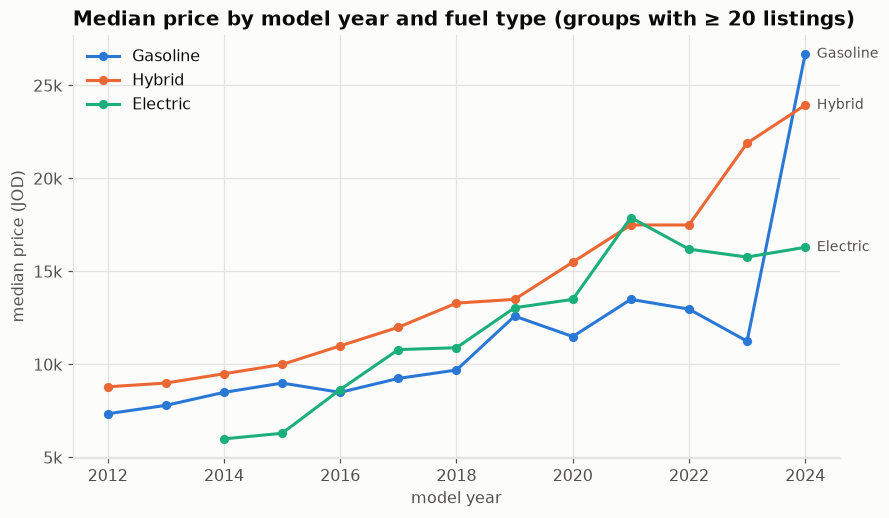

In [10]:
plausible = plausible.assign(year_n=pd.to_numeric(plausible["year"], errors="coerce"))
fuels = ["Gasoline", "Hybrid", "Electric"]
sub = plausible[plausible["year_n"].between(2012, 2024) & plausible["fuel_type"].isin(fuels)]
g = sub.groupby(["year_n", "fuel_type"])[TARGET].agg(["median", "count"]).reset_index()
g = g[g["count"] >= 20]  # hide noisy points

fig, ax = plt.subplots(figsize=(9, 5))
for color, fuel in zip(SERIES, fuels):
    s = g[g["fuel_type"] == fuel]
    ax.plot(s["year_n"], s["median"], color=color, marker="o", markersize=5, label=fuel)
    last = s.iloc[-1]
    ax.text(last["year_n"] + 0.2, last["median"], fuel, color=TEXT_2, va="center", fontsize=9)
ax.yaxis.set_major_formatter(FuncFormatter(jod))
ax.set_title("Median price by model year and fuel type (groups with ≥ 20 listings)")
ax.set_xlabel("model year"); ax.set_ylabel("median price (JOD)")
ax.legend(loc="upper left")
fig.savefig(FIGURES / "fig04_depreciation_by_fuel.png"); plt.show()

- Price rises with model year (newer = more expensive) — **age will be one of the strongest features**.
- The 2024 gasoline jump is a **mix effect**, not a market trend: only ~40 listings, about 3 in 4 are SUVs
  (Jetour, Land Rover, Toyota…). Medians of small groups move with *which* cars are in them.
- For the same model year, **hybrids keep more value than electric cars** in recent years. Older EVs (2012–2016) are the
  cheapest group: battery age and fast-moving technology hit their resale value.

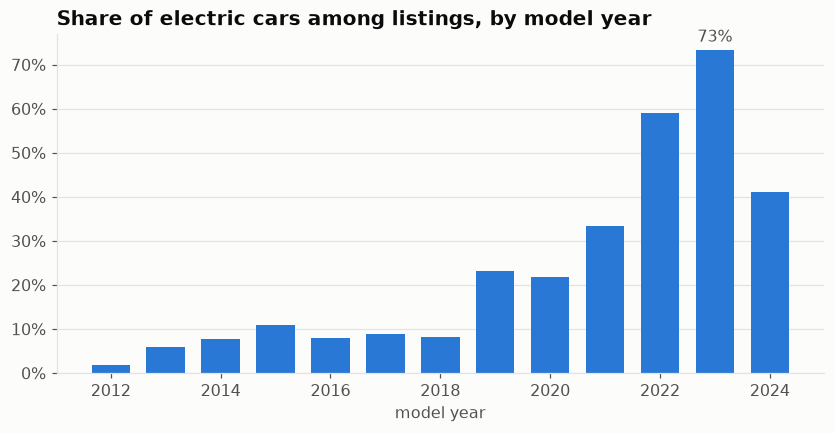

In [11]:
share = (plausible[plausible["year_n"].between(2012, 2024)]
         .groupby("year_n")["fuel_type"].apply(lambda s: (s == "Electric").mean()))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(share.index, share.values, color=SEQ, width=0.7)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="x", visible=False)
ax.set_title("Share of electric cars among listings, by model year")
ax.set_xlabel("model year")
peak = share.idxmax()
ax.text(peak, share[peak] + 0.02, f"{share[peak]:.0%}", ha="center", color=TEXT_2)
fig.savefig(FIGURES / "fig05_ev_share.png"); plt.show()

**A very Jordanian story:** among cars from model year 2023, the majority of listings are **electric**.
Jordan's lower customs on EVs made them a huge share of imports. A model trained here must handle EVs well —
which is why the battery columns matter.

## 6 · Mileage

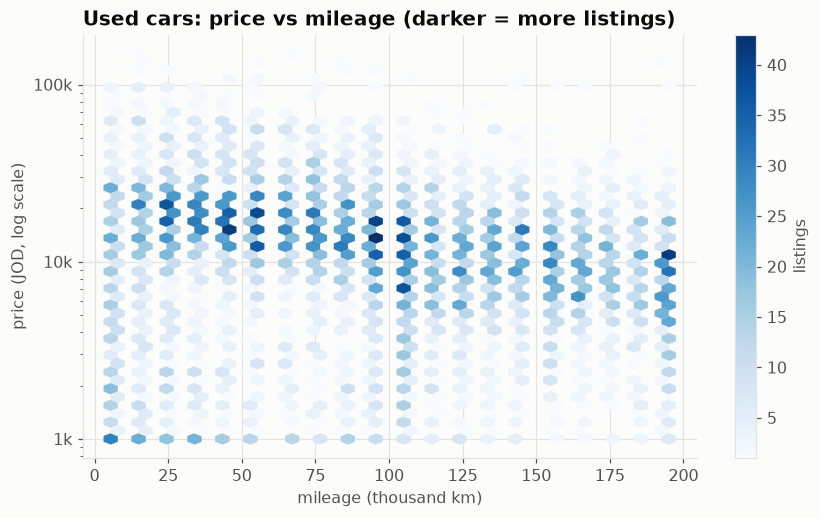

Spearman correlation (mileage vs price): -0.19


In [12]:
used = plausible[(plausible["condition"] == "Used") & plausible["mileage_km"].notna()]
fig, ax = plt.subplots(figsize=(9, 5))
hb = ax.hexbin(used["mileage_km"] / 1000, used[TARGET], gridsize=40, yscale="log",
               cmap="Blues", mincnt=1, linewidths=0.2)
ax.set_title("Used cars: price vs mileage (darker = more listings)")
ax.set_xlabel("mileage (thousand km)"); ax.set_ylabel("price (JOD, log scale)")
ax.yaxis.set_major_formatter(FuncFormatter(jod))
fig.colorbar(hb, ax=ax, label="listings")
fig.savefig(FIGURES / "fig06_price_vs_mileage.png"); plt.show()
print("Spearman correlation (mileage vs price):", round(used["mileage_km"].corr(used[TARGET], method="spearman"), 2))

More kilometres → lower price, but the cloud is wide: mileage and age are linked (old cars have more km).
A good model has to separate these effects — tree models do this naturally.
The dark strip at **~1k JOD across all mileages** is suspicious: real 2–5 year-old cars are not sold for 1,000 JOD —
these look like "call me" / down-payment prices. We'll handle that band in cleaning.
Note the vertical stripes: `mileage_km` is stored as the **top of a 10,000 km bracket** (e.g. 154,999).

## 7 · City, condition, customs

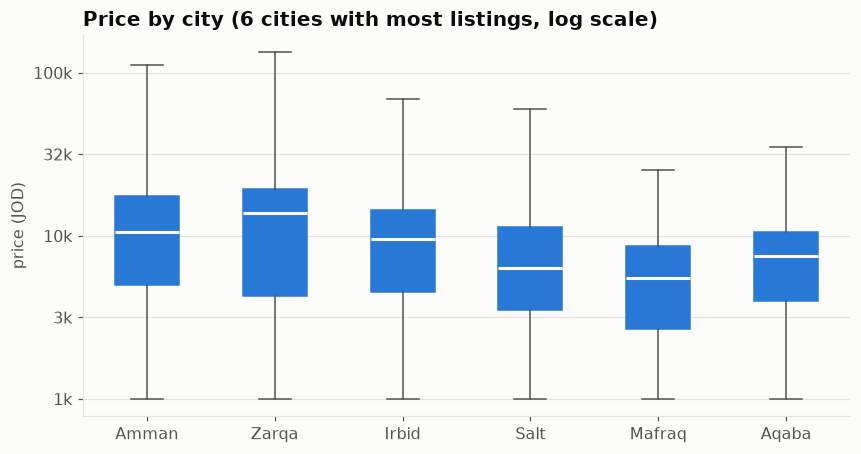

,median,count
city,,
Amman,10500.0,6154
Zarqa,13900.0,1435
Irbid,9600.0,1011
Salt,6350.0,190
Mafraq,5500.0,134
Aqaba,7500.0,111


In [13]:
top_cities = plausible["city"].value_counts().head(6).index
data = [np.log10(plausible.loc[plausible["city"] == c, TARGET]) for c in top_cities]
fig, ax = plt.subplots(figsize=(9, 4.5))
bp = ax.boxplot(data, tick_labels=top_cities, showfliers=False, patch_artist=True,
                medianprops=dict(color="white", linewidth=2),
                whiskerprops=dict(color=TEXT_2), capprops=dict(color=TEXT_2))
for b in bp["boxes"]:
    b.set(facecolor=SEQ, edgecolor=SEQ)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: jod(10 ** v)))
ax.set_title("Price by city (6 cities with most listings, log scale)")
ax.set_ylabel("price (JOD)"); ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "fig07_price_by_city.png"); plt.show()
plausible.groupby("city")[TARGET].agg(["median", "count"]).sort_values("count", ascending=False).head(6)

**Zarqa has a higher median than Amman.** That's local knowledge: the **Zarqa Free Zone** is Jordan's main car
market, where many newer, imported cars are listed. (A correlation, not a cause: the city is a proxy for *which cars* are sold there.)

In [14]:
for col in ["condition", "feat_carcustoms", "transmission"]:
    display(plausible.groupby(col)[TARGET].agg(["median", "count"]).round(0))

,median,count
condition,,
New,14500.0,872
Used,9750.0,8633


,median,count
feat_carcustoms,,
With Customs,10000.0,9175
Without Customs,13975.0,328


,median,count
transmission,,
Automatic,11200.0,8411
Manual,2800.0,1091


- **New** cars are pricier than used ones — expected.
- Cars **without customs** have a *higher* median. Surprising? These are mostly newer cars in the free zone,
  so again the feature carries information about *which* cars, not just about the tax.

## 8 · What we learned → decisions for the next phase

| Finding | Decision |
|---|---|
| 636 empty rows, ~1.2k without price, ~700 duplicates | drop them |
| Placeholder prices (999,999 / 1,000,000 / 7M) and "call me" prices (< 1,000) | keep a plausible range, documented |
| Price is right-skewed | train on `log(price)` |
| `year` is text ("Older than 1970") | convert to number → **car age = 2024 − year** |
| `mileage_km` missing for ~20% of used cars | impute + add a `mileage_missing` flag |
| Battery columns empty for non-EVs | fill with `"None"` (missing = meaningful) |
| 95 brands, 628 models (high cardinality) | group rare models; use tree models / target-aware encoding |
| Brand, age, fuel type, city drive price | expect them at the top of feature importance |

Next notebook: **cleaning + feature engineering as a tested `Pipeline`**.